## Performance Plots of Exponential Run for Results Figure

In [1]:
# imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

summary_dir = Path("/Users/liviastein/STDP_Theta-1/Results_expScale/summaryTables")

# files contain condition, seed, number episodes, counts, percentage correct, duration to goal
files = {
    "clean_theta": summary_dir / "Clean00_seed_summary_table.csv",
    "scrambled_0.2": summary_dir / "ScrExp02_seed_summary_table.csv",
    "scrambled_0.4": summary_dir / "ScrExp04_seed_summary_table.csv",
    "scrambled_0.6": summary_dir / "ScrExp06_seed_summary_table.csv",
    "scrambled_0.8": summary_dir / "ScrExp08_seed_summary_table.csv",
    "scrambled_1.0": summary_dir / "ScrExp1_seed_summary_table.csv",
}

summary_frames = []
for condition_name, path in files.items():
    df = pd.read_csv(path)
    # Rename theta_condition values to standardized names
    df["theta_condition"] = condition_name
    summary_frames.append(df)

all_seed_summary = pd.concat(summary_frames, ignore_index=True)
all_seed_summary

,theta_condition,seed,total_episodes,reached_goal,wrong_arm,timeouts,percentage_correct,average_time_to_goal
0,clean_theta,0,10,8,0,2,0.8,50.343750
1,clean_theta,2,10,7,1,2,0.7,49.298571
2,clean_theta,4,10,10,0,0,1.0,53.063000
3,clean_theta,6,10,8,0,2,0.8,50.445000
4,clean_theta,42,10,8,0,2,0.8,55.768750
5,scrambled_0.2,0,10,4,0,6,0.4,51.667500
6,scrambled_0.2,2,10,6,1,3,0.6,58.180000
7,scrambled_0.2,4,10,4,0,6,0.4,60.510000
8,scrambled_0.2,6,10,5,0,5,0.5,56.370000
9,scrambled_0.2,42,10,5,0,5,0.5,48.392000


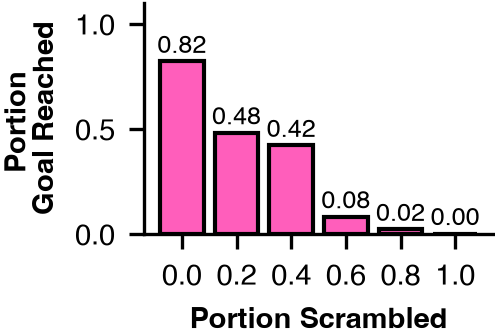

In [8]:
#plt.style.use("seaborn-v0_8-whitegrid")
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')
Livi_palette1 = ['#ff66c4', '#2AF5FF', '#531CB3', '#0CBABA', '#2191FB', '#FFB800', '#FF5733']
#define new palette with labels for each hex colour, so colours can be called by label instead of index
Livi_palette = {
    "türkis": '#66dfd8',
    "lBlue": '#1097d3',
    "dViolet": '#5e17eb',
    "lpurple": '#8c52ff',
    "altRosa": '#cb6ce6',
    "lRosa": '#e2a9f1',
    "pink": '#ff5ebb'
}

# Order conditions
condition_order = ["clean_theta", "scrambled_0.2", "scrambled_0.4", "scrambled_0.6", "scrambled_0.8", "scrambled_1.0"]

# Calculate mean percentage correct per condition
percentage_by_condition = all_seed_summary.groupby("theta_condition")["percentage_correct"].mean()
percentage_by_condition = percentage_by_condition.reindex(condition_order)

# Create bar plot with colors from palette
fig, axes = plt.subplots(figsize=(1.5, 1.0))
#colors = [Livi_palette[i % len(Livi_palette)] for i in range(len(percentage_by_condition))]
#ax.bar(range(len(percentage_by_condition)), percentage_by_condition.values, color=colors, edgecolor='#531CB3', linewidth=1.5)
axes.bar(range(len(percentage_by_condition)), percentage_by_condition.values, color= Livi_palette["pink"], edgecolor="black")
axes.labelweight = 'bold'
# Set x-axis labels
axes.set_xticks(range(len(percentage_by_condition)))
x_labels = ["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"]
axes.set_xticklabels(x_labels, rotation=0, ha='center')

# Set labels and title
axes.set_ylabel("Portion \nGoal Reached", fontweight='bold') 
axes.set_xlabel("Portion Scrambled", fontweight='bold')
#plt.suptitle("Performance Across Theta Conditions", fontsize=24, fontweight='bold')
#ax.set_title("Performance Across 5 Seeds with 10 Episodes Each", fontsize=16, fontstyle='italic')
axes.set_ylim(0, 1.1)

#axes.spines['top'].set_visible(True)

# Add value labels on bars
for i, v in enumerate(percentage_by_condition.values):
    axes.text(i, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize =6)

#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/PortionGoalReached_15_small.png", transparent=True)
#plt.tight_layout()
plt.show()

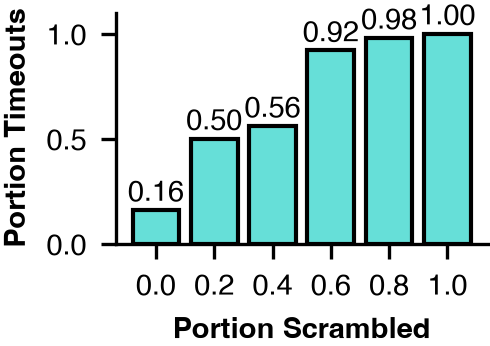

In [9]:
#plt.style.use("seaborn-v0_8-whitegrid")
Livi_palette1 = ['#ff66c4', '#2AF5FF', '#531CB3', '#0CBABA', '#2191FB', '#FFB800', '#FF5733']

# Order conditions
condition_order = ["clean_theta", "scrambled_0.2", "scrambled_0.4", "scrambled_0.6", "scrambled_0.8", "scrambled_1.0"]

# Calculate percentage of timeouts per seed, then mean across seeds per condition
all_seed_summary["timeout_percentage"] = all_seed_summary["timeouts"] / all_seed_summary["total_episodes"]
timeouts_percentage_by_condition = all_seed_summary.groupby("theta_condition")["timeout_percentage"].mean()
timeouts_percentage_by_condition = timeouts_percentage_by_condition.reindex(condition_order)

# Create bar plot with colors from palette
figure, axes = plt.subplots(figsize=(1.6, 1.0))
#figure.facecolor = None
#axes.facecolor = None
#colors = [Livi_palette[i % len(Livi_palette)] for i in range(len(timeouts_percentage_by_condition))]
axes.bar(range(len(timeouts_percentage_by_condition)), timeouts_percentage_by_condition.values, color=Livi_palette["türkis"], edgecolor='black')

# Set x-axis labels
axes.set_xticks(range(len(timeouts_percentage_by_condition)))
x_labels = ["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"]
axes.set_xticklabels(x_labels, rotation=0, ha='center')

# Set labels and title
axes.set_ylabel("Portion Timeouts", fontweight='bold')
axes.set_xlabel("Portion Scrambled")
#plt.suptitle("Timeouts Across Theta Conditions", fontsize=24, fontweight='bold')
#axes.set_title("Timeouts Across 5 Seeds with 10 Episodes Each", fontsize=16, fontstyle='italic')
axes.set_ylim(0, 1.1)

# Add value labels on bars
for i, v in enumerate(timeouts_percentage_by_condition.values):
    axes.text(i, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=7) # with rounded values

# save figure
#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/PortionTimeouts_15_small.pdf", transparent=True)

#plt.tight_layout()
plt.show()

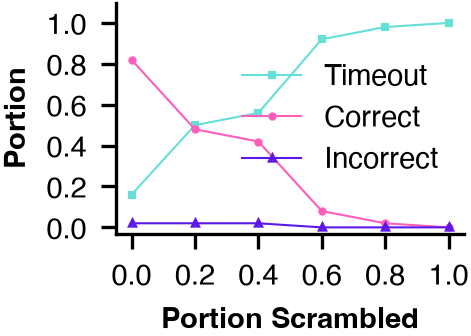

In [10]:
#plt.style.use("seaborn-v0_8-whitegrid")
Livi_palette1 = ['#ff66c4', '#2AF5FF', '#531CB3', '#0CBABA', '#2191FB', '#FFB800', '#FF5733']
Livi_palette = {
    "türkis": '#66dfd8',
    "lBlue": '#1097d3',
    "dViolet": '#5e17eb',
    "lpurple": '#8c52ff',
    "altRosa": '#cb6ce6',
    "lRosa": '#e2a9f1',
    "pink": '#ff5ebb'
}

# Order conditions
condition_order = ["clean_theta", "scrambled_0.2", "scrambled_0.4", "scrambled_0.6", "scrambled_0.8", "scrambled_1.0"]
x_labels = ["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"]
x_positions = range(len(condition_order))

# Calculate percentages per condition
all_seed_summary["timeout_percentage"] = all_seed_summary["timeouts"] / all_seed_summary["total_episodes"]
all_seed_summary["wrong_arm_percentage"] = all_seed_summary["wrong_arm"] / all_seed_summary["total_episodes"]

goal_reached_by_condition = all_seed_summary.groupby("theta_condition")["percentage_correct"].mean().reindex(condition_order)
timeout_pct_by_condition = all_seed_summary.groupby("theta_condition")["timeout_percentage"].mean().reindex(condition_order)
wrong_arm_pct_by_condition = all_seed_summary.groupby("theta_condition")["wrong_arm_percentage"].mean().reindex(condition_order)
#time_to_goal_by_condition = all_seed_summary.groupby("theta_condition")["average_time_to_goal"].mean().reindex(condition_order)

# Create line plot
fig, ax = plt.subplots(figsize=(1.5, 1.0))
ax.plot(x_positions, timeout_pct_by_condition.values, marker='s' , linewidth= 0.5, label='Timeout', color=Livi_palette['türkis'])
ax.plot(x_positions, goal_reached_by_condition.values, marker='o', linewidth= 0.5, label='Correct', color=Livi_palette['pink'])
ax.plot(x_positions, wrong_arm_pct_by_condition.values, marker='^', linewidth= 0.5, label='Incorrect', color=Livi_palette['dViolet'])
# add line for average time to goal across conditions when goal is reached
#ax.plot(x_positions, time_to_goal_by_condition.values, marker='d', linewidth= 0.5, label='Time to Goal', color=Livi_palette['lBlue'])

# Set x-axis labels
ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=0, ha='center')
ax.set_yticks(np.arange(0, 1.1, 0.2))  # Set y-ticks from 0 to 1 with step of 0.2

# Set labels and title
ax.set_ylabel("Portion")
ax.set_xlabel("Portion Scrambled")
#plt.suptitle("Performance Metrics Across Theta Conditions", fontsize=24, fontweight='bold')
#ax.set_title("Percentage Goal Reached, Timeouts, and Wrong Arm Choices", fontsize=16, fontstyle='italic')
ax.set_ylim(-0.03, 1.1)

# Add legend
ax.legend(loc='right', fontsize=7)

# Add grid
#ax.grid(True, alpha=0.3)

# save figure
#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/PerformanceMetricCurves_15.pdf", transparent=True)

#plt.tight_layout()
plt.show()

## Navigation Efficienty

In [12]:
allEpisodes = Path("/Users/liviastein/STDP_Theta-1/Results_expScale/summaryTables/r_export/all_episode_tables.csv")

dfEpisodes = pd.read_csv(allEpisodes)

# check the first few rows of the dataframe
summary= dfEpisodes.head()

# check the data types of each column
dfEpisodes.dtypes

# replace na values in the "scramble_strength" column with 1.0
dfEpisodes["scramble_strength"] = dfEpisodes["scramble_strength"].fillna(1.0)
dfEpisodes["scramble_strength"].isna().sum()

# change order of scramble_strength array and transform into categorical variable 
#dfEpisodes["scramble_strength"] = pd.Categorical(dfEpisodes["scramble_strength"], categories=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0], ordered=True)
dfEpisodes["scramble_strength"].unique()
dfEpisodes.dtypes # check data types again

# check mean duration per scramble category
mean_duration = dfEpisodes.groupby("scramble_strength")["duration"].mean()
# get standard error of the mean duration per scramble category
sem_duration = dfEpisodes.groupby("scramble_strength")["duration"].sem()
print(mean_duration)
print(sem_duration)
#print(summary)
#dfEpisodes.head()


scramble_strength
1.0    79.367833
Name: duration, dtype: float64
scramble_strength
1.0    1.001967
Name: duration, dtype: float64


In [ ]:
# DO THE STATS FIRST -> NEXT IS PLOTTING

import scikit_posthocs as sp  # for Dunn's test
from itertools import permutations # in case I need this later 
# test for overall differences between groups first using kruskal-wallis test
from scipy.stats import kruskal

df_successful = dfEpisodes[dfEpisodes["reward_count"] == 1]
# Filter out rows with NaN values in the "duration" column
df_successful = df_successful[df_successful["duration"].notna()]
# perform test
kruskal_result = kruskal(*[df_successful[df_successful["scramble_strength"] == g]["duration"] for g in [0.0, 0.2, 0.4]])
print("Kruskal-Wallis test result:", kruskal_result)



dunn_results = sp.posthoc_dunn(
    df_successful, val_col="duration", group_col="scramble_strength", p_adjust="fdr_bh"
)
dunn_results 
print(dunn_results)

comparisons = [(0.0, 0.2), (0.0, 0.4), (0.2, 0.4)]

def adjacent_values(vals, q1, q3):
    upper_adjacent_value = q3 + (q3 - q1) * 1.5
    upper_adjacent_value = np.clip(upper_adjacent_value, q3, vals[-1])
    lower_adjacent_value = q1 - (q3 - q1) * 1.5
    lower_adjacent_value = np.clip(lower_adjacent_value, vals[0], q1)
    return lower_adjacent_value, upper_adjacent_value

# ensure clean numeric columns
df_successful["duration"] = pd.to_numeric(df_successful["duration"], errors="coerce")
df_successful["scramble_strength"] = pd.to_numeric(df_successful["scramble_strength"], errors="coerce")
df_successful = df_successful.dropna(subset=["duration", "scramble_strength"])

groups = [0.0, 0.2, 0.4]
data_by_group = []
plot_groups = []

for g in groups:
    vals = df_successful.loc[df_successful["scramble_strength"] == g, "duration"].to_numpy()
    if len(vals) > 0:
        data_by_group.append(vals)
        plot_groups.append(g)

fig, ax = plt.subplots(figsize=(1.5, 1.0))
parts = ax.violinplot(data_by_group, positions=range(1, len(plot_groups) + 1),
                       showmeans=False, showmedians=False, showextrema=False, bw_method=0.4)

colors = ["#66dfd8", "#ff5ebb", "#ff5ebb"]
for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color)
    pc.set_alpha(0.5)
    pc.set_linewidth(0.3)
    pc.set_edgecolor("black")

quartile1, medians, quartile3, whiskers_min, whiskers_max = [], [], [], [], []
for group_data in data_by_group:
    sorted_vals = np.sort(group_data)
    q1, med, q3 = np.percentile(sorted_vals, [25, 50, 75])
    w_min, w_max = adjacent_values(sorted_vals, q1, q3)
    quartile1.append(q1); medians.append(med); quartile3.append(q3)
    whiskers_min.append(w_min); whiskers_max.append(w_max)

inds = np.arange(1, len(medians) + 1)
# jitter of actual data points, colored per group
rng = np.random.default_rng(42)
jitter_colors = ["#66dfd8", "#ff5ebb", "#ff5ebb"]
for i, (group_data, color) in enumerate(zip(data_by_group, jitter_colors)):
    x_pos = i + 1
    x_jitter = rng.normal(loc=x_pos, scale=0.2, size=len(group_data))
    ax.scatter(x_jitter, group_data, color=color, alpha=1, s=2, zorder=1, edgecolors='none')

ax.scatter(inds, medians, marker='o', color='white', s=0.5, zorder=3)
ax.vlines(inds, quartile1, quartile3, color='black', linestyle='-', lw=2.5, alpha=1.0)
ax.vlines(inds, whiskers_min, whiskers_max, color='black', linestyle='-', lw=0.5)

ax.set_xticks(range(1, len(plot_groups) + 1))
# set y ticks for specific values, e.g., 0, 5, 10, 15, 20
ax.set_yticks([50, 70, 90, 110])
ax.set_xticklabels([f"{g:.1f}" for g in plot_groups])
ax.set_xlabel("Portion Scrambled")
ax.set_ylabel("Duration to Goal (s)")
#ax.set_title("Navigation Efficiency")

def p_to_stars(p):
    if p < 0.0001: return "****"
    elif p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return "ns"

# --- significance brackets (manual) ---
y_max = df_successful["duration"].max()
bracket_height_step = (y_max * 0.08)  # spacing between stacked brackets
current_y = y_max + bracket_height_step

positions = [1, 2, 3]  # x positions for the groups
# choose your p-value source: dunn_results (matrix) or perm_pvals_adj (dict)
for comp in comparisons:
    g1, g2 = comp
    p = dunn_results.loc[g1, g2]          # now correctly assigned
    stars = p_to_stars(p)
    
    x1 = positions[groups.index(g1)]
    x2 = positions[groups.index(g2)]
    
    ax.plot([x1, x1, x2, x2], 
             [current_y, current_y + bracket_height_step*0.1, current_y + bracket_height_step*0.1, current_y], 
             color="black", linewidth=0.5, alpha=0.4)
    ax.text((x1 + x2) / 2, current_y -1, stars, # y
             ha="center", va="bottom", fontsize=6, alpha=0.8)
    
    current_y += bracket_height_step*1.1   # stack next bracket higher

#plt.tight_layout()

#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/NavigationEfficiency_small.png", transparent=True)
plt.show()